<a href="https://colab.research.google.com/github/eunnypark/Hohmann-Transfer/blob/main/Hohmann_Transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== [표] 목표 궤도 반경 변화에 따른 호만 전이 역학적 지표 비교 ===
 Target Radius (r2)  Semi-major Axis (a)  Delta-v 1 (dv1)  Delta-v 2 (dv2)  Total Delta-v (Sum dv)  Transfer Time (T)
                2.0                  1.5           0.1547           0.1298                  0.2845             5.7715
                3.0                  2.0           0.2247           0.1691                  0.3938             8.8858
                4.0                  2.5           0.2649           0.1838                  0.4487            12.4182
                5.0                  3.0           0.2910           0.1890                  0.4800            16.3242




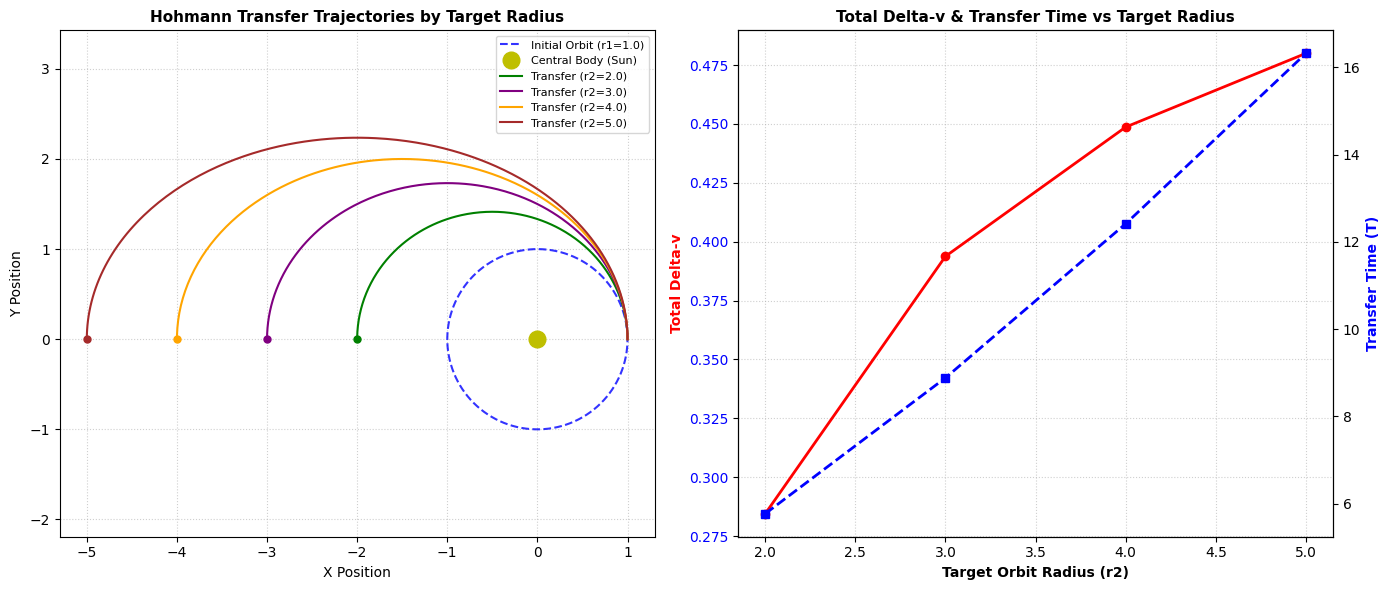

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 시뮬레이션 환경 및 물리 상수 설정 (정규화된 단위 GM = 1.0)
GM = 1.0
r1 = 1.0  # 출발 궤도 반지름 (동일하게 유지할 기준 조건)

# 비교 실험을 위한 목표 궤도 반지름 목록 (변경 조건)
r2_list = [2.0, 3.0, 4.0, 5.0]

results = []

# 2. 쏜튼과 매리언 일반역학 공식에 기반한 호만 전이 이론값 계산
for r2 in r2_list:
    # 출발 및 목표 원운동 속도
    v1 = np.sqrt(GM / r1)
    v2 = np.sqrt(GM / r2)

    # 전이 타원의 긴반경 (Semi-major axis, a = (r1 + r2) / 2)
    a = (r1 + r2) / 2.0

    # 전이 궤도 진입 시 속도(근점 v_t1)와 탈출 시 속도(원점 v_t2)
    v_t1 = np.sqrt(GM * (2.0 / r1 - 1.0 / a))
    v_t2 = np.sqrt(GM * (2.0 / r2 - 1.0 / a))

    # 각 지점에서의 속도 변화량 (Delta-v)
    dv1 = abs(v_t1 - v1)
    dv2 = abs(v2 - v_t2)
    total_dv = dv1 + dv2

    # 전이 소요 시간 (케플러 제3법칙에 따른 타원 주기의 절반)
    transfer_time = np.pi * np.sqrt(a**3 / GM)

    # 경고를 일으키는 특수문자 및 LaTeX 기호를 제거하여 깔끔한 텍스트로 정리
    results.append({
        'Target Radius (r2)': r2,
        'Semi-major Axis (a)': round(a, 4),
        'Delta-v 1 (dv1)': round(dv1, 4),
        'Delta-v 2 (dv2)': round(dv2, 4),
        'Total Delta-v (Sum dv)': round(total_dv, 4),
        'Transfer Time (T)': round(transfer_time, 4)
    })

# 3. 데이터프레임을 활용한 비교 표(Table) 생성 및 출력
df_results = pd.DataFrame(results)
print("=== [표] 목표 궤도 반경 변화에 따른 호만 전이 역학적 지표 비교 ===")
print(df_results.to_string(index=False))
print("\n" + "="*60 + "\n")

# 4. 결과 시각화 (Matplotlib을 활용한 복수 그래프 렌더링)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# [좌측 그래프] 다양한 r2 조건별 호만 전이 궤도 기하학적 비교
ax1 = axes[0]
theta = np.linspace(0, 2 * np.pi, 500)
# 출발 궤도
ax1.plot(r1 * np.cos(theta), r1 * np.sin(theta), 'b--', label=f'Initial Orbit (r1={r1})', alpha=0.8)
ax1.plot(0, 0, 'yo', markersize=12, label='Central Body (Sun)')

colors = ['green', 'purple', 'orange', 'brown']
for idx, r2 in enumerate(r2_list):
    a = (r1 + r2) / 2.0
    e = (r2 - r1) / (r1 + r2)
    p = a * (1.0 - e**2)
    theta_trans = np.linspace(0, np.pi, 300)
    r_trans = p / (1.0 + e * np.cos(theta_trans))
    x_trans = r_trans * np.cos(theta_trans)
    y_trans = r_trans * np.sin(theta_trans)

    ax1.plot(x_trans, y_trans, color=colors[idx], label=f'Transfer (r2={r2})', linewidth=1.5)
    ax1.plot(-r2, 0, 'o', color=colors[idx], markersize=5)

ax1.set_title('Hohmann Transfer Trajectories by Target Radius', fontsize=11, fontweight='bold')
ax1.set_xlabel('X Position')
ax1.set_ylabel('Y Position')
ax1.legend(loc='upper right', fontsize=8)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.axis('equal')

# [우측 그래프] 목표 반지름 변화에 따른 총 Delta-v와 소요 시간 추이 비교
ax2 = axes[1]
r2_arr = np.array(r2_list)
total_dv_arr = [row['Total Delta-v (Sum dv)'] for row in results]
time_arr = [row['Transfer Time (T)'] for row in results]

ax2.plot(r2_arr, total_dv_arr, 'ro-', label='Total Delta-v', linewidth=2)
ax2.set_xlabel('Target Orbit Radius (r2)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Total Delta-v', color='r', fontsize=10, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='r')
ax2.grid(True, linestyle=':', alpha=0.6)

ax2_twin = ax2.twinx()
ax2_twin.plot(r2_arr, time_arr, 'bs--', label='Transfer Time', linewidth=2)
ax2_twin.set_ylabel('Transfer Time (T)', color='b', fontsize=10, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='b')

plt.title('Total Delta-v & Transfer Time vs Target Radius', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()